# Part 2 - 02 Transfer learning: frozen MobileNetV2 base and new classification head

In [1]:
import tensorflow as tf
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

import os
import sys

REPO = "/workspace/NeuroVision"

sys.path.append(f"{REPO}/src")
os.chdir(f"{REPO}/notebooks")
for folder in ("models", "reports"):
    os.makedirs(f"{REPO}/{folder}", exist_ok=True)

2026-10-29 11:42:40.039219: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793274160.065285   10499 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793274160.073177   10499 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793274160.093322   10499 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793274160.093339   10499 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793274160.093341   10499 computation_placer.cc:177] computation placer alr

## Imports and configuration

In [2]:
import time

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import mlflow
from neurovision.tracking import MlflowEpochLogger, log_training_summary, setup_mlflow, start_run
from sklearn.utils.class_weight import compute_class_weight

from neurovision.data import CLASSES
from neurovision.preprocessing import prepare_data, make_dataset, encoder
from neurovision.transfer import IMAGE_SIZE, build_transfer_model, get_base, count_parameters

RAW_DIR = "../data/raw"
WEIGHTS = "imagenet"
EPOCHS_HEAD = 50

## Load the data (same cleaning and split as Part 1) and compute class weights on train only

In [3]:
data = prepare_data(RAW_DIR, size=IMAGE_SIZE, seed=42)
X_train, y_train, p_train = data["train"]
X_val, y_val, p_val = data["val"]
X_test, y_test, p_test = data["test"]

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)

weights = compute_class_weight(
    "balanced", classes=np.arange(len(CLASSES)), y=encoder.transform(y_train)
)
class_weight = dict(enumerate(weights))
print(X_train.shape, X_val.shape, class_weight)

I0000 00:00:1793274187.561625   10499 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 10262 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:08:00.0, compute capability: 8.6


(4708, 224, 224, 3) (1009, 224, 224, 3) {0: np.float64(1.0379188712522045), 1: np.float64(1.0288461538461537), 2: np.float64(0.9711221122112211), 3: np.float64(0.9663382594417077)}


## Build the model: frozen MobileNetV2 base, global pooling, dropout, 4-neuron softmax head

In [4]:
model = build_transfer_model(weights=WEIGHTS)
model.summary()

trainable, non_trainable = count_parameters(model)
print(f"Trainable (head): {trainable:,}")
print(f"Non-trainable (frozen base): {non_trainable:,}")
print("Base trainable:", get_base(model).trainable)

Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocess            │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Trainable (head): 5,124
Non-trainable (frozen base): 2,257,984
Base trainable: False


## Callbacks: save the best model, stop early, resume after interruption

In [5]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "../models/transfer_best.keras", monitor="val_accuracy", save_best_only=True
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=7, restore_best_weights=True
    ),
    tf.keras.callbacks.BackupAndRestore(backup_dir="../models/backup_transfer"),
    MlflowEpochLogger(),
]

## Train the new head only and measure the training time

In [6]:
setup_mlflow()
start_run("transfer_head", tags={"stage": "training", "model_type": "mobilenetv2_transfer"})
mlflow.log_params({
    "epochs_max": EPOCHS_HEAD,
    "early_stopping_patience": 7,
    "weights": WEIGHTS,
    "seed": 42,
    "trainable_params": trainable,
    "non_trainable_params": non_trainable,
    "n_train": len(X_train),
    "n_val": len(X_val),
})

start = time.time()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    class_weight=class_weight,
    callbacks=callbacks,
)
head_minutes = (time.time() - start) / 60
log_training_summary(history, head_minutes * 60, model_path="../models/transfer_best.keras")
print(f"Head training time: {head_minutes:.1f} min for {len(history.history['loss'])} epoch(s)")

Epoch 1/50


I0000 00:00:1793274197.580926   10813 cuda_dnn.cc:529] Loaded cuDNN version 90300


148/148 ━━━━━━━━━━━━━━━━━━━━ 17s 72ms/step - accuracy: 0.7026 - loss: 0.7411 - val_accuracy: 0.8048 - val_loss: 0.4996
Epoch 2/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 9s 61ms/step - accuracy: 0.8311 - loss: 0.4517 - val_accuracy: 0.8385 - val_loss: 0.4202
Epoch 3/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 9s 59ms/step - accuracy: 0.8526 - loss: 0.3962 - val_accuracy: 0.8266 - val_loss: 0.4547
Epoch 4/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 9s 59ms/step - accuracy: 0.8683 - loss: 0.3655 - val_accuracy: 0.8325 - val_loss: 0.4197
Epoch 5/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 10s 66ms/step - accuracy: 0.8787 - loss: 0.3319 - val_accuracy: 0.8761 - val_loss: 0.3276
Epoch 6/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 9s 62ms/step - accuracy: 0.8777 - loss: 0.3326 - val_accuracy: 0.8731 - val_loss: 0.3369
Epoch 7/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 9s 59ms/step - accuracy: 0.8872 - loss: 0.3143 - val_accuracy: 0.8484 - val_loss: 0.4080
Epoch 8/50
148/148 ━━━━━━━━━━━━━━━━━━━━ 9s 59ms/step - accuracy: 0.8857 - loss: 0.3041 - val_accuracy: 0.8

## Learning curves: accuracy and loss

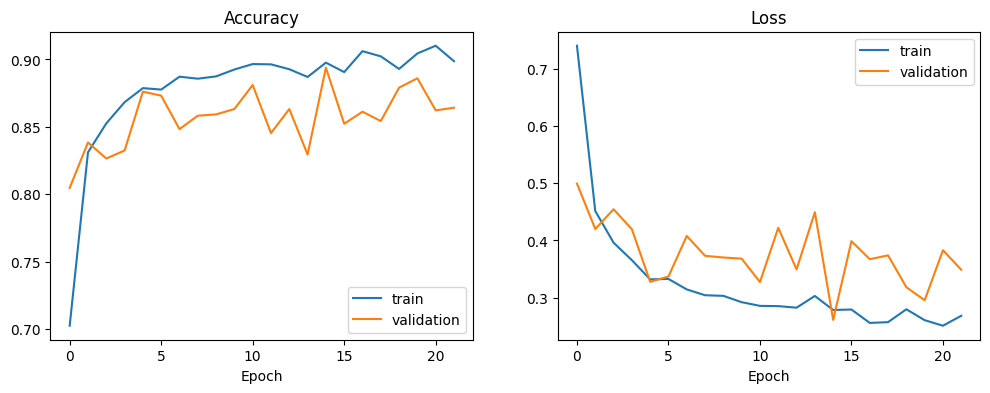

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.savefig("../reports/transfer_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

if mlflow.active_run():
    mlflow.log_artifact("../reports/transfer_learning_curves.png", "figures")

## Validation score before fine-tuning (the test set stays untouched)

In [8]:
val_loss, val_acc = model.evaluate(val_ds)
print(f"Validation loss: {val_loss:.4f} | Validation accuracy: {val_acc:.4f}")

if mlflow.active_run():
    mlflow.log_metrics({"val_loss_final": val_loss, "val_accuracy_final": val_acc})
    mlflow.end_run()

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.8940 - loss: 0.2609
Validation loss: 0.2609 | Validation accuracy: 0.8940
